# 04 · Why action is hard: open-loop vs closed-loop on a 2-link arm

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import show_video

ARM = """
<mujoco>
  <option timestep="0.002" gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 -1 2"/>
    <geom type="plane" size="1 1 .01" rgba=".9 .9 .9 1"/>
    <body name="l1" pos="0 0 .6">
      <joint name="j1" axis="0 1 0" damping=".05"/>
      <geom type="capsule" fromto="0 0 0 .3 0 0" size=".025" mass="{m1}" rgba=".2 .4 .8 1"/>
      <body name="l2" pos=".3 0 0">
        <joint name="j2" axis="0 1 0" damping=".05"/>
        <geom type="capsule" fromto="0 0 0 .25 0 0" size=".02" mass="{m2}" rgba=".8 .4 .2 1"/>
        <site name="tip" pos=".25 0 0" size=".02" rgba="1 0 0 1"/>
      </body>
    </body>
  </worldbody>
  <actuator>
    <motor joint="j1" ctrlrange="-30 30"/>
    <motor joint="j2" ctrlrange="-30 30"/>
  </actuator>
</mujoco>"""

def make(m1=1.0, m2=0.6):
    model = mujoco.MjModel.from_xml_string(ARM.format(m1=m1, m2=m2))
    return model, mujoco.MjData(model)

def reference(T=2.0, dt=0.002, q0=(0.0, 0.0), q1=(-1.2, -1.0)):
    t = np.arange(0, T, dt)
    u = t / T
    s = 10 * u**3 - 15 * u**4 + 6 * u**5
    sd = (30 * u**2 - 60 * u**3 + 30 * u**4) / T
    sdd = (60 * u - 180 * u**2 + 120 * u**3) / T**2
    dq = np.array(q1) - np.array(q0)
    return t, np.array(q0) + np.outer(s, dq), np.outer(sd, dq), np.outer(sdd, dq)

def feedforward_torques(model, data, q, qd, qdd):
    tau = []
    for i in range(len(q)):
        data.qpos[:], data.qvel[:], data.qacc[:] = q[i], qd[i], qdd[i]
        mujoco.mj_inverse(model, data)
        tau.append(data.qfrc_inverse.copy())
    return np.array(tau)

def rollout(model, data, tau_ff, q, qd, kp=0.0, kd=0.0, push_at=None, render=False):
    mujoco.mj_resetData(model, data)
    data.qpos[:] = q[0]
    tips, frames = [], []
    r = mujoco.Renderer(model, 240, 320) if render else None
    for i in range(len(tau_ff)):
        data.ctrl[:] = tau_ff[i] + kp * (q[i] - data.qpos) + kd * (qd[i] - data.qvel)
        data.xfrc_applied[:] = 0
        if push_at is not None and push_at <= i < push_at + 50:
            data.xfrc_applied[model.body("l2").id, :3] = [0, 0, -15]
        mujoco.mj_step(model, data)
        tips.append(data.site("tip").xpos[[0, 2]].copy())
        if render and i % 16 == 0:
            r.update_scene(data)
            frames.append(r.render())
    return np.array(tips), frames

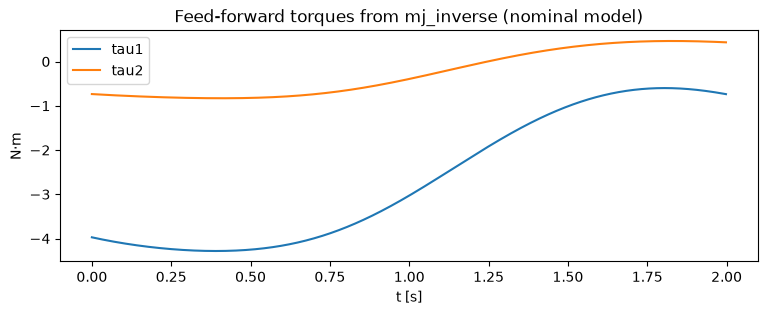

In [2]:
t, q, qd, qdd = reference()
nominal, nd = make()
tau_ff = feedforward_torques(nominal, nd, q, qd, qdd)
plt.figure(figsize=(9, 3))
plt.plot(t, tau_ff); plt.legend(["tau1", "tau2"]); plt.xlabel("t [s]"); plt.ylabel("N·m")
plt.title("Feed-forward torques from mj_inverse (nominal model)"); plt.show()

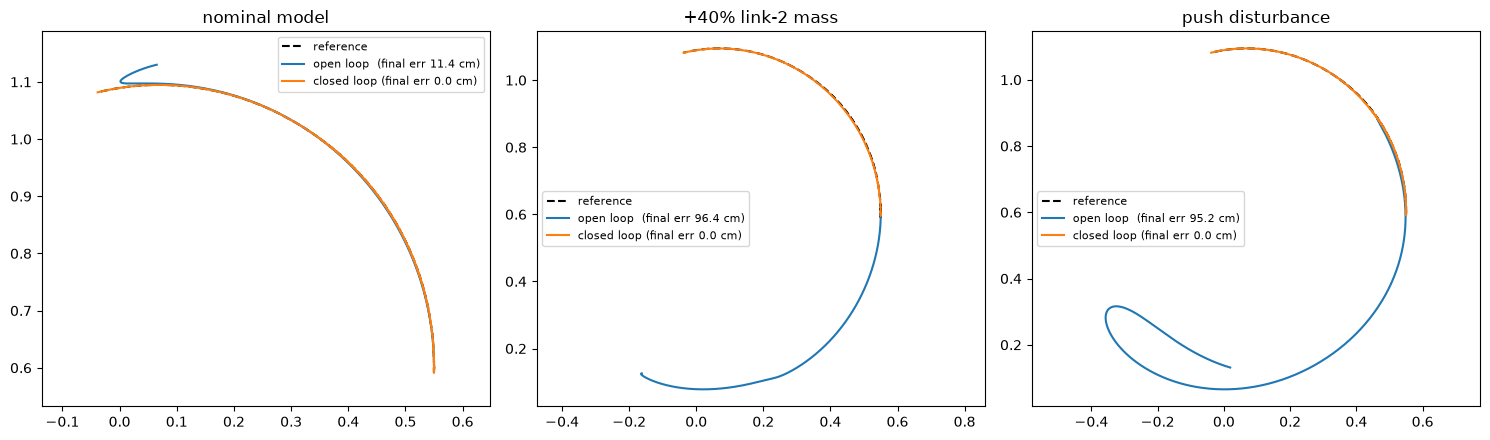

In [3]:
cases = {
    "nominal model": dict(model=make()),
    "+40% link-2 mass": dict(model=make(m2=0.84)),
    "push disturbance": dict(model=make(), push_at=400),
}
ref_tip, _ = rollout(*make(), tau_ff, q, qd, kp=100, kd=5)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, c) in zip(axes, cases.items()):
    model, data = c["model"]
    ol, _ = rollout(model, data, tau_ff, q, qd, push_at=c.get("push_at"))
    cl, _ = rollout(model, data, tau_ff, q, qd, kp=100, kd=5, push_at=c.get("push_at"))
    ax.plot(*ref_tip.T, "k--", label="reference")
    ax.plot(*ol.T, label=f"open loop  (final err {np.linalg.norm(ol[-1] - ref_tip[-1]) * 100:.1f} cm)")
    ax.plot(*cl.T, label=f"closed loop (final err {np.linalg.norm(cl[-1] - ref_tip[-1]) * 100:.1f} cm)")
    ax.set_title(name); ax.axis("equal"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
model, data = make(m2=0.84)
_, f_open = rollout(model, data, tau_ff, q, qd, render=True)
_, f_closed = rollout(model, data, tau_ff, q, qd, kp=100, kd=5, render=True)
show_video([np.hstack([a, b]) for a, b in zip(f_open, f_closed)], fps=30, title="open loop | closed loop")